# Metrik di luar akurasi dan keselarasan emosi

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab06_evaluasi/02_metrik_beyond_accuracy_dan_afektif.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 6 · Kode 6.x (coverage, Gini, novelty, ILD, EAS, QHR, KL afektif)

**Tujuan belajar**

- Menghitung coverage, Gini, novelty, ILD, EAS, QHR, dan KL afektif.
- Melihat pertukaran akurasi dan keragaman/keselarasan pada simulasi.
- Mengenali metrik yang bisa 'dicurangi' (EAS tinggi dengan rekomendasi netral).

> **Catatan jujur.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

## 1. Kode dari buku

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
import numpy as np

DIAG = 2 * np.sqrt(2)  # jarak terjauh dua titik di [-1, 1]^2


def coverage(lists, n_items):
    return len({i for L in lists for i in L}) / n_items


def gini(exposure):
    x = np.sort(np.asarray(exposure, float))
    n = len(x)
    return ((2 * np.arange(1, n + 1) - n - 1) * x).sum() / (n * x.sum())


def novelty(ranked, pop, n_users):
    return float(np.mean([-np.log2(pop[i] / n_users) for i in ranked]))


def ild(ranked, va):
    V = np.array([va[i] for i in ranked])
    d = [np.linalg.norm(V[a] - V[b]) / DIAG for a, b in combinations(range(len(V)), 2)]
    return float(np.mean(d))


def align(v, m):
    return 1.0 - np.linalg.norm(np.asarray(v) - np.asarray(m)) / DIAG


def quadrant(v):
    if v[0] >= 0:
        return 0 if v[1] >= 0 else 3
    return 1 if v[1] >= 0 else 2


def eas(ranked, va, m, weighted=False):
    a = np.array([align(va[i], m) for i in ranked])
    w = 1.0 / np.log2(np.arange(2, len(a) + 2)) if weighted else np.ones(len(a))
    return float((w * a).sum() / w.sum())


def qhr(ranked, va, m):
    return float(np.mean([quadrant(va[i]) == quadrant(m) for i in ranked]))


def affective_kl(ranked, va, p_hist, eps=0.01):
    q = np.bincount([quadrant(va[i]) for i in ranked], minlength=4) / len(ranked)
    p = np.asarray(p_hist, float)
    q_s = (1 - eps) * q + eps * p
    nz = p > 0
    return float((p[nz] * np.log2(p[nz] / q_s[nz])).sum())

## 2. Dunia simulasi

Katalog 400 item dengan koordinat valence–arousal di empat kuadran dan popularitas Zipf. Tiap pengguna punya mood saat ini `m` (salah satu pusat kuadran) dan relevansi stabil per item. Empat pembuat daftar (top-10 dari 50 kandidat relevansi tertinggi):

| Pembuat daftar | Cara memilih |
|---|---|
| **Populer** | 10 item paling populer, tanpa personalisasi |
| **Relevansi-saja** | 10 skor relevansi tertinggi |
| **Selaras-mood** | relevansi + bobot besar untuk kedekatan ke mood |
| **Netral** | item yang koordinatnya paling dekat ke pusat (0,0) |

In [2]:
rng = np.random.default_rng(0)
N_I, N_U, K = 400, 300, 10
PUSAT = np.array([[.6, .6], [-.6, .6], [-.6, -.6], [.6, -.6]])
va = np.clip(PUSAT[rng.integers(0, 4, N_I)] + rng.normal(0, .25, (N_I, 2)), -1, 1)
pop_cnt = rng.permutation(1000.0 / np.arange(1, N_I + 1) ** 0.9)         # jumlah interaksi per item
pop_cnt = np.maximum(pop_cnt, 1.0)
n_users_total = 1000

rel_u = rng.normal(0, 1, (N_U, N_I)) + 0.5 * np.log(pop_cnt / pop_cnt.mean())
mood_u = PUSAT[rng.integers(0, 4, N_U)]
# distribusi kuadran riwayat per pengguna (untuk KL): sebagian besar di kuadran mood-nya
p_hist = np.array([0.1 + 0.6 * (np.arange(4) == quadrant(m)) for m in mood_u])
p_hist /= p_hist.sum(1, keepdims=True)

def daftar(strategi):
    out = []
    for u in range(N_U):
        cand = np.argsort(-rel_u[u])[:50]
        if strategi == "Populer":
            L = list(np.argsort(-pop_cnt)[:K])
        elif strategi == "Relevansi-saja":
            L = list(cand[:K])
        elif strategi == "Selaras-mood":
            a = np.array([align(va[i], mood_u[u]) for i in cand])
            r = (rel_u[u][cand] - rel_u[u][cand].min()) / np.ptp(rel_u[u][cand])
            L = list(cand[np.argsort(-(0.4 * r + 0.6 * a))[:K]])
        else:                                                                # Netral
            L = list(cand[np.argsort(np.linalg.norm(va[cand], axis=1))[:K]])
        out.append(L)
    return out

strategi = ["Populer", "Relevansi-saja", "Selaras-mood", "Netral"]
L = {s: daftar(s) for s in strategi}

def ringkas(Ls):
    expo = np.bincount(np.concatenate(Ls), minlength=N_I)
    # relevansi (rata-rata z-skor relevansi item yang direkomendasikan) sebagai proksi akurasi
    rel_rata = np.mean([rel_u[u][Ls[u]].mean() for u in range(N_U)])
    return {"relevansi rata-rata": rel_rata,
            "coverage": coverage(Ls, N_I), "Gini eksposur": gini(expo),
            "novelty": np.mean([novelty(l, dict(enumerate(pop_cnt)), n_users_total) for l in Ls]),
            "ILD": np.mean([ild(l, va) for l in Ls]),
            "EAS": np.mean([eas(Ls[u], va, mood_u[u]) for u in range(N_U)]),
            "QHR": np.mean([qhr(Ls[u], va, mood_u[u]) for u in range(N_U)]),
            "KL afektif": np.mean([affective_kl(Ls[u], va, p_hist[u]) for u in range(N_U)])}

tab = pd.DataFrame({s: ringkas(L[s]) for s in strategi}).T
print(tab.round(3).to_string())

                relevansi rata-rata  coverage  Gini eksposur  novelty    ILD    EAS    QHR  KL afektif
Populer                       1.233     0.025          0.975    1.961  0.324  0.633  0.270       1.995
Relevansi-saja                2.315     0.922          0.644    4.418  0.395  0.616  0.268       1.165
Selaras-mood                  1.993     0.945          0.588    4.689  0.252  0.826  0.741       0.868
Netral                        1.484     0.315          0.833    5.568  0.279  0.662  0.260       1.058


## 3. Membaca tabel dan menguji klaim

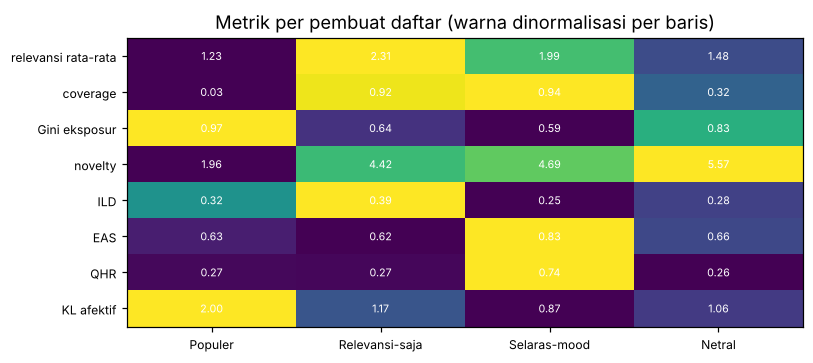

In [3]:
# Klaim-klaim di bawah dibuktikan oleh data simulasi, bukan diasumsikan.
assert tab.loc["Populer", "coverage"] < tab.loc["Relevansi-saja", "coverage"]       # populer: cakupan sempit
assert tab.loc["Populer", "Gini eksposur"] > tab.loc["Relevansi-saja", "Gini eksposur"]
assert tab.loc["Populer", "novelty"] < tab.loc["Relevansi-saja", "novelty"]         # populer: tidak baru
assert tab.loc["Relevansi-saja", "relevansi rata-rata"] > tab.loc["Selaras-mood", "relevansi rata-rata"]
assert tab.loc["Selaras-mood", "QHR"] > tab.loc["Relevansi-saja", "QHR"]
assert tab.loc["Selaras-mood", "EAS"] > tab.loc["Relevansi-saja", "EAS"]
# Jebakan: daftar netral menang di EAS secara murah, tetapi kalah di QHR dan keragaman afektif
assert tab.loc["Netral", "ILD"] < tab.loc["Relevansi-saja", "ILD"]
assert tab.loc["Netral", "QHR"] < tab.loc["Selaras-mood", "QHR"]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
z = (tab - tab.min()) / (tab.max() - tab.min() + 1e-12)
im = ax.imshow(z.T.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(z.index)), z.index, fontsize=8); ax.set_yticks(range(z.shape[1]), z.columns, fontsize=8)
for i in range(z.shape[1]):
    for j in range(z.shape[0]):
        ax.text(j, i, f"{tab.iloc[j, i]:.2f}", ha="center", va="center", color="w", fontsize=7)
ax.set_title("Metrik per pembuat daftar (warna dinormalisasi per baris)")
fig.tight_layout()

**Interpretasi (dari angka di atas).**

- **Populer** memiliki coverage dan novelty terendah serta Gini tertinggi: tidak personal, menumpuk eksposur pada sedikit item.
- **Relevansi-saja** paling relevan, tetapi tidak mempedulikan mood sehingga EAS dan QHR-nya lebih rendah daripada **Selaras-mood**.
- **Selaras-mood** menukar sedikit relevansi dengan keselarasan emosi yang jauh lebih baik. Pertukaran ini adalah inti Bab 5.
- **Netral** adalah jebakan: item di dekat pusat valence–arousal memiliki jarak sedang ke semua mood sehingga EAS-nya terlihat lumayan tanpa benar-benar cocok dengan mood siapa pun. QHR (kecocokan kuadran) dan ILD (keragaman) membongkarnya. Karena itu satu metrik afektif saja tidak cukup; laporkan beberapa yang saling mengimbangi. KL afektif terendah pada Selaras-mood: distribusi kuadran daftarnya paling dekat dengan riwayat pengguna (yang dalam simulasi ini condong ke kuadran mood).

## 4. Eksperimen: kurva pertukaran bobot afektif

Variasikan bobot mood `w` pada skor `(1-w)·relevansi + w·keselarasan`. Plot relevansi vs EAS/QHR.

In [4]:
def daftar_w(w):
    out = []
    for u in range(N_U):
        cand = np.argsort(-rel_u[u])[:50]
        a = np.array([align(va[i], mood_u[u]) for i in cand])
        r = (rel_u[u][cand] - rel_u[u][cand].min()) / np.ptp(rel_u[u][cand])
        out.append(list(cand[np.argsort(-((1 - w) * r + w * a))[:K]]))
    return out

rows = []
for w in (0.0, 0.2, 0.4, 0.6, 0.8, 1.0):
    Ls = daftar_w(w)
    rows.append({"w": w, "relevansi": np.mean([rel_u[u][Ls[u]].mean() for u in range(N_U)]),
                 "EAS": np.mean([eas(Ls[u], va, mood_u[u]) for u in range(N_U)]),
                 "QHR": np.mean([qhr(Ls[u], va, mood_u[u]) for u in range(N_U)]),
                 "ILD": np.mean([ild(Ls[u], va) for u in range(N_U)])})
kurva = pd.DataFrame(rows).set_index("w")
print(kurva.round(3))
assert kurva["relevansi"].is_monotonic_decreasing
assert kurva["QHR"].iloc[-1] > kurva["QHR"].iloc[0]
assert kurva["ILD"].iloc[-1] < kurva["ILD"].iloc[0]

     relevansi    EAS    QHR    ILD
w                                  
0.0      2.315  0.616  0.268  0.395
0.2      2.302  0.660  0.354  0.382
0.4      2.236  0.723  0.492  0.349
0.6      1.993  0.826  0.741  0.252
0.8      1.658  0.897  0.934  0.147
1.0      1.501  0.905  0.944  0.133


**Interpretasi.** Relevansi turun monoton ketika bobot afektif naik, sedangkan QHR dan EAS naik. ILD turun karena daftar makin mengumpul di satu area valence–arousal. Jadi mengejar keselarasan emosi memiliki harga ganda: relevansi dan keragaman. Pemilihan `w` adalah keputusan produk, bukan hanya statistik; kurva ini membantu membuat keputusan itu eksplisit.

## Pertanyaan refleksi

1. Mengapa `affective_kl` mencampur `q` dengan `p` (smoothing `eps`)? Apa yang terjadi bila `eps = 0` dan satu kuadran tidak pernah direkomendasikan?
2. Rancang pembuat daftar lain yang menaikkan EAS tetapi merusak QHR. Apakah ia lolos dari asersi?
3. Bagaimana mengubah novelty agar tidak bergantung pada `n_users_total` yang tidak diketahui pada sistem baru?